# Multitienda del Sur SpA - Entrega 1
**IIC 3752 · Tecnologías para Inteligencia de Negocios · Proyecto del semestre**

**Pregunta de negocio (README, pregunta 1):** ¿La cadena está reteniendo a sus clientes o los está reponiendo con compradores de una sola vez?

Este notebook es la **cadena de datos completa y reproducible** de la Entrega 1. Corre de cero en Google Colab con *Entorno de ejecución → Ejecutar todo* y produce todas las cifras, tablas y gráficos del informe.

| Sección | Qué hace | Componente del informe |
|---|---|---|
| 0 | Configuración, parámetros y descarga del repositorio | B |
| 1 | Extracción de las cuatro fuentes (SQLite, CSV, JSON, API IPC) | B |
| 2 | Limpieza con registro automático de cada regla | B, F |
| 3 | Modelo dimensional (dimensiones y tablas de hechos) | C |
| 4 | Métrica: retención de la base activa, bajo las dos definiciones | D |
| 5 | Caso de negocio en pesos reales | E |
| 6 | Cobertura de datos | F |
| 7 | Visualizaciones (5) y diagrama del modelo | C, E |
| 8 | Resumen de cifras del informe | todos |

## 0. Configuración
Si el notebook se abre en Colab, la primera celda clona el repositorio para tener los datos crudos en `data/raw/`. Si ya se está dentro del repositorio (ejecución local), no clona nada.

In [1]:
import os, subprocess

REPO_URL = "https://github.com/matiasbasm/retail_multitienda_grupo_12.git"
REPO_DIR = "retail_multitienda_grupo_12"

if not os.path.exists("data/raw/origen_pos.sqlite"):
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)

print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /content/retail_multitienda_grupo_12


In [2]:
import json, re, sqlite3, time, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
T0 = time.time()

# ---------------- Parámetros del análisis ----------------
ANIO = 2025
W_PRINCIPAL = 90        # días: ventana de actividad elegida (definición principal)
W_ALTERNATIVA = 30      # días: creencia verbalizada por la gerencia (definición alternativa)
VENTANAS_SENSIBILIDAD = [30, 45, 60, 75, 90]

# Fecha base: primer cierre de mes con 90 días completos de historia dentro de los datos
# (31-mar-2025 menos 90 días = 31-dic-2024, así la ventana (d-90, d] cae entera en 2025).
FECHA_BASE = pd.Timestamp("2025-03-31")
FECHA_CIERRE = pd.Timestamp("2025-12-31")

RAW, PROC = "data/raw", "data/processed"
FIG, TAB, DOCS = "outputs/figuras", "outputs/tablas", "docs"
for carpeta in (PROC, FIG, TAB, DOCS):
    os.makedirs(carpeta, exist_ok=True)

FUENTE_PIE = "Fuente: origen_pos.sqlite, boletas 2025 de clientes identificados. Elaboración propia, Grupo 12."

### Registro de limpieza
Cada regla de limpieza llama a `registrar(...)`. Al final, el registro se exporta a `outputs/tablas/registro_limpieza.csv` y alimenta directamente la bitácora de supuestos y la cobertura del informe. Así la documentación sale del mismo código que produce las cifras.

In [3]:
REGISTRO = []

def registrar(fuente, regla, afectados, total, accion, motivo, efecto_si_falso):
    """Agrega una fila al registro de limpieza y la muestra."""
    fila = {
        "n": len(REGISTRO) + 1,
        "fuente": fuente,
        "regla": regla,
        "registros_afectados": int(afectados),
        "total_registros": int(total),
        "pct_afectado": round(100 * afectados / total, 2) if total else 0.0,
        "accion": accion,
        "motivo": motivo,
        "efecto_si_el_supuesto_fuera_falso": efecto_si_falso,
    }
    REGISTRO.append(fila)
    print(f"[{fila['n']:02d}] {fuente} · {regla}: {afectados:,} de {total:,} ({fila['pct_afectado']}%) → {accion}")

## 1. Extracción de las cuatro fuentes
Se leen tal cual vienen. Ninguna transformación ocurre en esta sección.

In [4]:
# Fuente 1: base del punto de venta (SQLite)
con = sqlite3.connect(f"{RAW}/origen_pos.sqlite")
tablas_pos = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con)["name"].tolist()
pos = {t: pd.read_sql(f'SELECT * FROM "{t}"', con) for t in tablas_pos}
con.close()
for t, df in pos.items():
    print(f"POS · {t:15s} {len(df):>6,} filas")

# Fuente 2: maestro de productos (CSV, separador ';', codificación cp1252)
maestro_raw = pd.read_csv(f"{RAW}/origen_maestro_productos.csv", sep=";", encoding="cp1252", dtype=str)
print(f"\nMaestro de productos: {len(maestro_raw):,} filas")

# Fuente 3: promociones (JSON)
with open(f"{RAW}/origen_promociones.json", encoding="utf-8") as f:
    promos_raw = json.load(f)
print(f"Promociones: {len(promos_raw['campanas'])} campañas")

POS · regiones             5 filas
POS · comunas             12 filas
POS · tiendas             10 filas
POS · medios_pago          4 filas
POS · clientes         1,200 filas
POS · boletas          6,321 filas
POS · boleta_detalle  14,554 filas

Maestro de productos: 193 filas
Promociones: 2 campañas


In [5]:
# Fuente 4: API del IPC mensual (mindicador.cl), con respaldo local si la API no responde
def obtener_ipc(url=f"https://mindicador.cl/api/ipc/{ANIO}", cache=f"{RAW}/ipc_{ANIO}_cache.json"):
    try:
        r = requests.get(url, timeout=20)
        r.raise_for_status()
        data = r.json()
        meses = {pd.to_datetime(s["fecha"], utc=True).month for s in data["serie"]}
        if len(meses) < 12:
            raise ValueError(f"la API devolvió solo {len(meses)} meses")
        with open(f"{PROC}/ipc_{ANIO}_respuesta_api.json", "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False, indent=1)
        return data, "API mindicador.cl"
    except Exception as e:
        print(f"API no disponible ({e}); se usa el respaldo local {cache}")
        with open(cache, encoding="utf-8") as f:
            return json.load(f), "respaldo local (data/raw)"

ipc_raw, FUENTE_IPC = obtener_ipc()
print("IPC leído desde:", FUENTE_IPC, "·", len(ipc_raw["serie"]), "meses · unidad:", ipc_raw.get("unidad_medida"))

IPC leído desde: API mindicador.cl · 12 meses · unidad: Porcentaje


## 2. Limpieza
Funciones de parseo comunes. Los datos traen montos y fechas en varios formatos a la vez, así que cada función reconoce todos los formatos observados y devuelve nulo ante cualquier otro (esos casos quedan registrados).

In [6]:
MESES_ES = {"ene": 1, "feb": 2, "mar": 3, "abr": 4, "may": 5, "jun": 6,
            "jul": 7, "ago": 8, "sep": 9, "oct": 10, "nov": 11, "dic": 12}

def formato_fecha(x):
    x = str(x).strip()
    if re.fullmatch(r"\d{4}-\d{2}-\d{2}", x): return "AAAA-MM-DD"
    if re.fullmatch(r"\d{2}/\d{2}/\d{4}", x): return "DD/MM/AAAA"
    if re.fullmatch(r"\d{1,2}-[a-z]{3}-\d{4}", x): return "DD-mmm-AAAA"
    if re.fullmatch(r"\d{2}-\d{2}-\d{2}", x): return "DD-MM-AA"
    return "no reconocido"

def parse_fecha(x):
    x = str(x).strip()
    try:
        if re.fullmatch(r"\d{4}-\d{2}-\d{2}", x):
            return pd.Timestamp(x)
        m = re.fullmatch(r"(\d{2})/(\d{2})/(\d{4})", x)
        if m: return pd.Timestamp(int(m[3]), int(m[2]), int(m[1]))
        m = re.fullmatch(r"(\d{1,2})-([a-z]{3})-(\d{4})", x)
        if m: return pd.Timestamp(int(m[3]), MESES_ES[m[2]], int(m[1]))
        m = re.fullmatch(r"(\d{2})-(\d{2})-(\d{2})", x)
        if m: return pd.Timestamp(2000 + int(m[3]), int(m[2]), int(m[1]))
    except (ValueError, KeyError):
        pass
    return pd.NaT

PATRON_MONTO = re.compile(r"-?\$?(\d{1,3}(\.\d{3})+|\.\d{3}|\d+)(,\d+)?")

def parse_monto(x):
    """'$1.168' -> 1168 · '1.190,00' -> 1190 · '3.459' -> 3459 · '3691' -> 3691 · '-.769' -> -769
    (punto = miles, coma = decimal)."""
    s = str(x).strip().replace(" ", "")
    if not PATRON_MONTO.fullmatch(s):
        return np.nan
    s = s.replace("$", "").replace(".", "").replace(",", ".")
    return float(s)

def parse_descuento(x):
    """'10%' -> 0.10 · '0,10' -> 0.10 · '10' -> 0.10 · '0' -> 0.0"""
    s = str(x).strip()
    if s.endswith("%"):
        return float(s[:-1].replace(",", ".")) / 100
    v = float(s.replace(",", "."))
    return v / 100 if v >= 1 else v

### 2.1 Boletas (cabecera)

In [7]:
boletas = pos["boletas"].copy()
n_boletas_orig = len(boletas)

# Regla: duplicados exactos
dup = boletas.duplicated()
registrar("POS · boletas", "Filas duplicadas exactas (mismo boleta_id y todos los campos iguales)",
          dup.sum(), n_boletas_orig, "Eliminadas (se conserva una)",
          "Es la misma transacción cargada dos veces.",
          "Si fueran compras distintas, la frecuencia de esos clientes estaría levemente subestimada.")
boletas = boletas[~dup].copy()

# Regla: formatos de fecha
formatos = boletas["fecha"].map(formato_fecha)
print("\nFormatos de fecha encontrados:\n", formatos.value_counts().to_string(), "\n")
boletas["fecha_dt"] = boletas["fecha"].map(parse_fecha)
n_fmt = (formatos != "AAAA-MM-DD").sum()
registrar("POS · boletas", "Fechas en formato distinto de AAAA-MM-DD (DD/MM/AAAA, DD-mmm-AAAA, DD-MM-AA)",
          n_fmt, len(boletas), "Convertidas a fecha estándar",
          "Cuatro formatos conviven en la misma columna; se interpretan día-mes-año (formato chileno).",
          "Si algún DD/MM fuera MM/DD, esas boletas caerían en otro mes; afecta solo fechas con día ≤ 12.")
no_parse = boletas["fecha_dt"].isna()
registrar("POS · boletas", "Fecha no interpretable", no_parse.sum(), len(boletas), "Eliminadas",
          "Sin fecha no se puede ubicar la compra en el tiempo.", "—")
boletas = boletas[~no_parse].copy()

# Regla: fuera del período de análisis
fuera = boletas["fecha_dt"].dt.year != ANIO
registrar("POS · boletas", f"Fecha fuera de {ANIO} (todas en 2026)", fuera.sum(), len(boletas), "Eliminadas",
          f"El caso cubre el año {ANIO}; fechas en 2026 son posteriores a la extracción y probablemente errores de digitación del año.",
          "Si fueran compras de 2025 con el año mal digitado, se pierde ~0,6% de las boletas; no cambia la conclusión.")
boletas = boletas[~fuera].copy()

# Regla: columna 'mes' inconsistente con la fecha
mes_inc = boletas["mes"].astype(int) != boletas["fecha_dt"].dt.month
registrar("POS · boletas", "Columna 'mes' no coincide con el mes de la fecha", mes_inc.sum(), len(boletas),
          "Columna descartada; se usa 'fecha'",
          "La columna 'mes' contradice la fecha en ~7% de los casos y es redundante.",
          "Si 'mes' fuera la correcta, esas boletas cambiarían de mes; la métrica usa ventanas de días, no meses calendario de esa columna.")

# Regla: columna 'region' de la boleta inconsistente con la región de la tienda
tiendas_reg = (pos["tiendas"].merge(pos["comunas"], on="comuna_id", how="left")
               .merge(pos["regiones"], on="region_id", how="left"))
reg_tienda = boletas["tienda_id"].map(tiendas_reg.set_index("tienda_id")["region"])
reg_inc = (boletas["region"] != reg_tienda) & reg_tienda.notna()
registrar("POS · boletas", "Columna 'region' de la boleta distinta de la región de su tienda", reg_inc.sum(), len(boletas),
          "Columna descartada; la región se toma de tienda → comuna → región",
          "La región es atributo de la tienda; un dato repetido en la boleta que la contradice no es confiable.",
          "Solo afectaría cortes por región, que no son parte de la métrica principal.")

boletas = boletas.drop(columns=["mes", "region"])
print(f"\nBoletas tras limpieza de cabecera: {len(boletas):,}")

[01] POS · boletas · Filas duplicadas exactas (mismo boleta_id y todos los campos iguales): 62 de 6,321 (0.98%) → Eliminadas (se conserva una)

Formatos de fecha encontrados:
 fecha
DD-MM-AA       1588
AAAA-MM-DD     1582
DD/MM/AAAA     1547
DD-mmm-AAAA    1542 

[02] POS · boletas · Fechas en formato distinto de AAAA-MM-DD (DD/MM/AAAA, DD-mmm-AAAA, DD-MM-AA): 4,677 de 6,259 (74.72%) → Convertidas a fecha estándar
[03] POS · boletas · Fecha no interpretable: 0 de 6,259 (0.0%) → Eliminadas
[04] POS · boletas · Fecha fuera de 2025 (todas en 2026): 37 de 6,259 (0.59%) → Eliminadas
[05] POS · boletas · Columna 'mes' no coincide con el mes de la fecha: 397 de 6,222 (6.38%) → Columna descartada; se usa 'fecha'
[06] POS · boletas · Columna 'region' de la boleta distinta de la región de su tienda: 356 de 6,222 (5.72%) → Columna descartada; la región se toma de tienda → comuna → región

Boletas tras limpieza de cabecera: 6,222


### 2.2 Detalle de boletas (líneas)

In [8]:
det = pos["boleta_detalle"].copy()
n_det_orig = len(det)

# Líneas de boletas eliminadas en 2.1
huerf = ~det["boleta_id"].isin(boletas["boleta_id"])
registrar("POS · boleta_detalle", "Líneas de boletas eliminadas en la limpieza de cabecera (fuera de 2025)",
          huerf.sum(), n_det_orig, "Eliminadas", "Pertenecen a boletas fuera del período.", "—")
det = det[~huerf].copy()

# Montos y descuentos
for col_orig, col_new in [("precio_unitario", "precio_unitario_n"), ("monto_linea", "monto_linea_n")]:
    det[col_new] = det[col_orig].map(parse_monto)
    con_punto = det[col_orig].astype(str).str.contains(r"\.").sum()
    registrar("POS · boleta_detalle", f"'{col_orig}' escrito con punto de miles (ej. '3.459')", con_punto, len(det),
              "Convertido a número (3.459 → 3459)",
              "El punto es separador de miles; los precios del maestro van de ~$750 a ~$10.000.",
              "Si el punto fuera decimal, los montos serían 1.000 veces menores y no cuadrarían con cantidad × precio.")
sin_entero = det["monto_linea"].astype(str).str.fullmatch(r"-\.\d{3}")
registrar("POS · boleta_detalle", "monto_linea negativo sin dígito antes del punto (ej. '-.769')", sin_entero.sum(), len(det),
          "Interpretado como −769", "Coincide exactamente con cantidad (−1) × precio × (1 − descuento) de la misma línea.", "—")
assert det[["precio_unitario_n", "monto_linea_n"]].notna().all().all(), "Hay montos no interpretables"

det["descuento_n"] = det["descuento"].map(parse_descuento)
desc_fmt = det["descuento"].astype(str)
n_desc = (~desc_fmt.isin(["0"]) & ~desc_fmt.str.endswith("%")).sum()
registrar("POS · boleta_detalle", "Descuento escrito como '10' o '0,10' en vez de '10%'", n_desc, len(det),
          "Normalizado a fracción (0,10)", "Tres notaciones para el mismo descuento.",
          "Si '10' significara $10 y no 10%, el monto neto cambiaría; pero el monto se toma de 'monto_linea' (regla siguiente).")

# Consistencia monto_linea vs cantidad × precio × (1 − descuento)
det["monto_calculado"] = det["cantidad"] * det["precio_unitario_n"] * (1 - det["descuento_n"])
inc = (det["monto_linea_n"] - det["monto_calculado"]).abs() > 2
registrar("POS · boleta_detalle", "monto_linea difiere de cantidad × precio × (1 − descuento) en más de $2",
          inc.sum(), len(det), "Se conserva 'monto_linea' como fuente de verdad",
          "'monto_linea' es el monto efectivamente cobrado en la boleta (el que se informa al SII).",
          "Si el correcto fuera el calculado, el gasto por cliente cambiaría marginalmente; la métrica de retención no usa montos.")

# Numeración de línea repetida dentro de una boleta
lin_rep = det.duplicated(["boleta_id", "linea"], keep=False)
registrar("POS · boleta_detalle", "Número de línea repetido dentro de la misma boleta (con SKU distinto)",
          lin_rep.sum(), len(det), "Conservadas (no son duplicados)",
          "Las líneas tienen productos distintos: es un error de numeración, no una línea cargada dos veces.",
          "Si fueran duplicados, el monto de ~3% de las boletas estaría sobrestimado.")

# Cantidades negativas (devoluciones)
neg = det["cantidad"] < 0
registrar("POS · boleta_detalle", "Cantidad negativa (devolución)", neg.sum(), len(det),
          "Conservadas: se netean dentro de su boleta",
          "Una devolución resta del monto de la boleta en que se registró.",
          "Si fueran errores de signo, el monto de esas boletas estaría subestimado.")

# SKU: normalización y cruce con el maestro (el maestro se limpia en 2.4; aquí solo se normaliza el texto)
det["sku"] = det["sku"].astype(str).str.strip().str.upper()

# Monto neto por boleta y exclusión de boletas con monto ≤ 0
monto_boleta = det.groupby("boleta_id")["monto_linea_n"].sum()
boletas["monto_nominal"] = boletas["boleta_id"].map(monto_boleta)
no_compra = boletas["monto_nominal"] <= 0
registrar("POS · boletas", "Boleta con monto neto ≤ 0 (solo devoluciones)", no_compra.sum(), len(boletas),
          "Excluidas del análisis de actividad",
          "Una boleta que solo devuelve productos no es una visita de compra; no debe contar como señal de retención.",
          "Si se contaran como visitas, algunos clientes aparecerían activos sin haber comprado.")
boletas_validas = boletas[~no_compra].copy()
det = det[det["boleta_id"].isin(boletas_validas["boleta_id"])].copy()
print(f"\nBoletas válidas: {len(boletas_validas):,} · líneas válidas: {len(det):,}")

[07] POS · boleta_detalle · Líneas de boletas eliminadas en la limpieza de cabecera (fuera de 2025): 83 de 14,554 (0.57%) → Eliminadas
[08] POS · boleta_detalle · 'precio_unitario' escrito con punto de miles (ej. '3.459'): 6,555 de 14,471 (45.3%) → Convertido a número (3.459 → 3459)
[09] POS · boleta_detalle · 'monto_linea' escrito con punto de miles (ej. '3.459'): 6,898 de 14,471 (47.67%) → Convertido a número (3.459 → 3459)
[10] POS · boleta_detalle · monto_linea negativo sin dígito antes del punto (ej. '-.769'): 2 de 14,471 (0.01%) → Interpretado como −769
[11] POS · boleta_detalle · Descuento escrito como '10' o '0,10' en vez de '10%': 2,538 de 14,471 (17.54%) → Normalizado a fracción (0,10)
[12] POS · boleta_detalle · monto_linea difiere de cantidad × precio × (1 − descuento) en más de $2: 722 de 14,471 (4.99%) → Se conserva 'monto_linea' como fuente de verdad
[13] POS · boleta_detalle · Número de línea repetido dentro de la misma boleta (con SKU distinto): 808 de 14,471 (5.58%) →

### 2.3 Clientes, tiendas y geografía

In [9]:
clientes = pos["clientes"].copy()
n_cli = len(clientes)

fmt_alta = clientes["fecha_alta"].map(formato_fecha)
clientes["fecha_alta_dt"] = clientes["fecha_alta"].map(parse_fecha)
registrar("POS · clientes", "fecha_alta en formato DD/MM/AAAA", (fmt_alta != "AAAA-MM-DD").sum(), n_cli,
          "Convertida a fecha estándar", "Dos formatos conviven en la columna.", "—")
assert clientes["fecha_alta_dt"].notna().all()

rut_sin_guion = ~clientes["rut"].astype(str).str.contains("-")
clientes["rut_norm"] = clientes["rut"].astype(str).str.replace(r"[^0-9kK]", "", regex=True).str.upper()
registrar("POS · clientes", "RUT sin guion ni dígito verificador separado", rut_sin_guion.sum(), n_cli,
          "Normalizado (solo dígitos); se verificó que no genera duplicados",
          "Para detectar clientes repetidos con distinto formato de RUT.",
          f"Duplicados tras normalizar: {clientes['rut_norm'].duplicated().sum()}.")

# Hallazgo: fecha_alta vs primera compra (verbalizado: 'la fecha de alta es su primera compra')
primera = (boletas_validas.dropna(subset=["cliente_id"])
           .groupby("cliente_id")["fecha_dt"].min())
clientes["primera_compra_2025"] = clientes["cliente_id"].map(primera)
dif = (clientes["primera_compra_2025"] - clientes["fecha_alta_dt"]).dt.days
registrar("POS · clientes", "fecha_alta distinta de la primera compra registrada", (dif != 0).sum(), n_cli,
          "Sin cambios en los datos; 'nuevo' se define por fecha_alta (ver sección 4)",
          "La contraparte dijo que la fecha de alta es la primera compra; los datos lo contradicen (366 altas son de 2024).",
          "Si se usara la primera compra observada, todos los clientes parecerían adquiridos en 2025 y se sobrestimaría la reposición.")

# Comunas: La Florida apunta a una región inexistente
comunas = pos["comunas"].copy()
reg_inexist = ~comunas["region_id"].isin(pos["regiones"]["region_id"])
print("\nComunas con región inexistente:\n", comunas[reg_inexist].to_string(index=False))
registrar("POS · comunas", "region_id que no existe en la tabla regiones (La Florida → 9)", reg_inexist.sum(), len(comunas),
          "Corregida a 1 (Metropolitana)", "La Florida es una comuna de la Región Metropolitana.",
          "Sin corregir, la tienda Express La Florida quedaría sin región.")
comunas.loc[comunas["comuna"].str.strip() == "La Florida", "region_id"] = 1

# Anónimos
anon = boletas_validas["cliente_id"].isna()
registrar("POS · boletas", "Boleta sin cliente identificado (compra anónima)", anon.sum(), len(boletas_validas),
          "Conservadas para ventas totales; excluidas de la métrica de retención",
          "Sin tarjeta no se puede atribuir la compra a una persona ni seguirla en el tiempo.",
          "La contraparte cree que hay clientes frecuentes que no pasan la tarjeta: la retención real podría ser mayor.")

# Canal online (verbalizado: 'partimos hace poco y solo en Providencia')
web = boletas_validas[boletas_validas["canal"] == "Web"]
print(f"\nCanal Web: {len(web):,} boletas ({len(web)/len(boletas_validas):.1%}), "
      f"desde {web['fecha_dt'].min():%d-%m-%Y}; tiendas: {web['tienda_id'].unique().tolist()}")

[16] POS · clientes · fecha_alta en formato DD/MM/AAAA: 601 de 1,200 (50.08%) → Convertida a fecha estándar
[17] POS · clientes · RUT sin guion ni dígito verificador separado: 243 de 1,200 (20.25%) → Normalizado (solo dígitos); se verificó que no genera duplicados
[18] POS · clientes · fecha_alta distinta de la primera compra registrada: 1,189 de 1,200 (99.08%) → Sin cambios en los datos; 'nuevo' se define por fecha_alta (ver sección 4)

Comunas con región inexistente:
  comuna_id     comuna  region_id
         4 La Florida          9
[19] POS · comunas · region_id que no existe en la tabla regiones (La Florida → 9): 1 de 12 (8.33%) → Corregida a 1 (Metropolitana)
[20] POS · boletas · Boleta sin cliente identificado (compra anónima): 804 de 6,173 (13.02%) → Conservadas para ventas totales; excluidas de la métrica de retención

Canal Web: 1,568 boletas (25.4%), desde 01-01-2025; tiendas: [10]


### 2.4 Maestro de productos

In [10]:
m = maestro_raw.copy()
n_m = len(m)

basura = (m["sku"].str.strip().str.lower() == "sku") | (m["sku"].str.strip().str.upper() == "TOTAL")
registrar("Maestro (CSV)", "Filas que no son productos (encabezado repetido, fila TOTAL)", basura.sum(), n_m,
          "Eliminadas", "Restos de una planilla exportada a mano.", "—")
m = m[~basura].copy()
m["sku"] = m["sku"].str.strip().str.upper()
m["nombre"] = m["nombre"].str.strip()

dup_sku = m["sku"].duplicated(keep="first")
print("SKU duplicados:\n", m[m["sku"].isin(m.loc[dup_sku, "sku"])].to_string(index=False))
registrar("Maestro (CSV)", "SKU repetido", dup_sku.sum(), len(m),
          "Se conserva la primera fila (la que está activa)",
          "La segunda fila está marcada inactiva y tiene el nombre en mayúsculas con espacios: es un registro antiguo.",
          "Si la vigente fuera la segunda, el costo de ese SKU cambiaría en ~2%.")
m = m[~dup_sku].copy()

MAPA_CATEGORIA = {
    "abarrotes": "Abarrotes", "abarr": "Abarrotes",
    "bebidas": "Bebidas", "beb": "Bebidas",
    "snacks": "Snacks", "snk": "Snacks",
    "lacteos": "Lácteos", "lácteos": "Lácteos", "lact": "Lácteos",
    "limpieza": "Limpieza", "aseo": "Limpieza",
    "perfumeria": "Perfumería", "perfumería": "Perfumería", "perf": "Perfumería",
    "carnes": "Carnes", "carn": "Carnes",
    "panaderia": "Panadería", "panadería": "Panadería", "pan": "Panadería",
}
cat_orig = m["categoria"].str.strip()
m["categoria"] = cat_orig.str.lower().map(MAPA_CATEGORIA)
print("\nCategorías originales → normalizadas:\n",
      pd.crosstab(cat_orig, m["categoria"]).replace(0, "").to_string())
assert m["categoria"].notna().all(), "Hay categorías sin mapear"
registrar("Maestro (CSV)", "Categoría escrita de forma no estándar (abreviada, minúsculas, sin tilde)",
          (cat_orig != m["categoria"]).sum(), len(m), "Normalizada a 8 categorías",
          "Ej.: 'LACT', 'lacteos' y 'Lácteos' son la misma categoría. 'ASEO' se asimila a Limpieza.",
          "Si ASEO fuera una categoría distinta, cambia solo el corte por categoría, no la métrica.")

m["costo_unitario"] = m["costo_unitario"].map(parse_monto)
m["precio_lista"] = m["precio_lista"].map(parse_monto)
registrar("Maestro (CSV)", "Precio de lista con '$' o con decimales ('1.190,00')",
          (~maestro_raw.loc[m.index, "precio_lista"].str.fullmatch(r"\d+")).sum(), len(m),
          "Convertido a número", "Tres formatos de precio en la misma columna.", "—")
m["activo"] = m["activo"].str.strip().str.lower().isin(["si", "sí", "1"])

sku_sin_maestro = ~det["sku"].isin(m["sku"])
print("\nSKU vendidos que no están en el maestro:", sorted(det.loc[sku_sin_maestro, "sku"].unique()))
registrar("POS · boleta_detalle", "Línea con SKU que no existe en el maestro de productos", sku_sin_maestro.sum(), len(det),
          "Conservadas para ventas; sin costo ni categoría (margen no calculable)",
          "El POS y el ERP no comparten la misma fuente de productos (verbalizado en la entrevista).",
          "El margen bruto se calcula sobre el resto de las líneas.")
maestro = m.reset_index(drop=True)

[21] Maestro (CSV) · Filas que no son productos (encabezado repetido, fila TOTAL): 2 de 193 (1.04%) → Eliminadas
SKU duplicados:
      sku           nombre categoria      subcategoria   marca proveedor costo_unitario precio_lista activo
SKU-0001 Arroz Tucapel F1 abarrotes Arroz y legumbres Tucapel   Tucapel            783       $1.168     si
SKU-0001 ARROZ TUCAPEL F1     ABARR Arroz y legumbres Tucapel   Tucapel            800     1.190,00     No
[22] Maestro (CSV) · SKU repetido: 1 de 191 (0.52%) → Se conserva la primera fila (la que está activa)

Categorías originales → normalizadas:
 categoria  Abarrotes Bebidas Carnes Limpieza Lácteos Panadería Perfumería Snacks
categoria                                                                       
ABARR              5                                                            
ASEO                                       3                                    
Abarrotes          9                                                            
B

### 2.5 Promociones e IPC

In [11]:
camp_rows, camp_sku_rows = [], []
for c in promos_raw["campanas"]:
    d = c["descuento_pct"]
    d = float(str(d).replace("%", "").replace(",", ".")) / 100 if isinstance(d, str) or d > 1 else float(d)
    camp_rows.append({"campana_id": c["campana_id"], "nombre": c["nombre"], "tipo": c["tipo"],
                      "fecha_ini": pd.Timestamp(c["fecha_ini"]), "fecha_fin": pd.Timestamp(c["fecha_fin"]),
                      "descuento_pct": d, "canales": ", ".join(c["canales"])})
    for s in c["skus"]:
        camp_sku_rows.append({"campana_id": c["campana_id"], "sku": s.strip().upper()})
campanas = pd.DataFrame(camp_rows)
campana_sku = pd.DataFrame(camp_sku_rows)
registrar("Promociones (JSON)", "descuento_pct en dos notaciones ('25%' y 50)", 2, len(campanas),
          "Normalizado a fracción", "Mismo campo, distinto tipo de dato.", "—")
fuera_maestro = ~campana_sku["sku"].isin(maestro["sku"])
registrar("Promociones (JSON)", "SKU en promoción que no existe en el maestro", fuera_maestro.sum(), len(campana_sku),
          "Conservados en la dimensión campaña; no cruzan con ventas",
          "No hay ventas de esos SKU; probablemente códigos internos de Marketing.", "—")
print(campanas.to_string(index=False))

# IPC: la API entrega la VARIACIÓN mensual en %, no un índice. Se encadena para construir el índice.
ipc = pd.DataFrame(ipc_raw["serie"])
# Las fechas vienen como medianoche de Chile expresada en UTC (ej. '2025-05-01T04:00:00.000Z').
# Se lee la fecha en UTC (día 1 del mes); convertir a hora de Chile la movería al mes anterior.
ipc["mes"] = pd.to_datetime(ipc["fecha"], utc=True).dt.tz_localize(None).dt.to_period("M")
assert ipc["mes"].is_unique and len(ipc) == 12, "La serie IPC debe tener 12 meses distintos"
ipc = ipc[ipc["mes"].dt.year == ANIO].sort_values("mes").reset_index(drop=True)
ipc["indice_dic2024_100"] = 100 * (1 + ipc["valor"] / 100).cumprod()
ipc["factor_a_pesos_dic"] = ipc["indice_dic2024_100"].iloc[-1] / ipc["indice_dic2024_100"]
registrar("API IPC", f"Origen de la serie IPC: {FUENTE_IPC}", len(ipc), 12,
          "Variaciones mensuales encadenadas en un índice (dic-2024 = 100)",
          "La API entrega variación mensual (%), no nivel; para deflactar se necesita el índice.",
          "La empresa hoy deflacta con 3% fijo; la inflación real de 2025 fue "
          f"{ipc['indice_dic2024_100'].iloc[-1] - 100:.1f}%, con meses negativos.")
print(ipc[["mes", "valor", "indice_dic2024_100", "factor_a_pesos_dic"]].round(4).to_string(index=False))

[26] Promociones (JSON) · descuento_pct en dos notaciones ('25%' y 50): 2 de 2 (100.0%) → Normalizado a fracción
[27] Promociones (JSON) · SKU en promoción que no existe en el maestro: 2 de 23 (8.7%) → Conservados en la dimensión campaña; no cruzan con ventas
  campana_id                nombre              tipo  fecha_ini           fecha_fin  descuento_pct         canales
CAMP-2025-09 Septiembre Imperdible descuento_directo 2025-09-01 2025-09-30 23:59:59           0.25 Presencial, Web
CAMP-2025-05         Otoño Lácteos               2x1 2025-05-05 2025-05-20 23:59:59           0.50      Presencial
[28] API IPC · Origen de la serie IPC: API mindicador.cl: 12 de 12 (100.0%) → Variaciones mensuales encadenadas en un índice (dic-2024 = 100)
    mes  valor  indice_dic2024_100  factor_a_pesos_dic
2025-01    1.1            101.1000              1.0232
2025-02    0.4            101.5044              1.0191
2025-03    0.5            102.0119              1.0140
2025-04    0.2            102.215

## 3. Modelo dimensional

**Tabla de hechos principal — `fact_boleta`.** *Una fila es una boleta válida emitida en 2025* (sin duplicados, con fecha en 2025 y monto neto mayor que cero).

**Tabla de hechos de soporte — `fact_cliente_mes` (snapshot periódico).** *Una fila es un cliente identificado al cierre de un mes de 2025*, desde el mes de su primera compra registrada, con los días transcurridos desde su última compra y su estado bajo cada ventana. La métrica de retención se calcula sobre esta tabla.

**Dimensiones:** fecha, cliente, tienda (con formato, canal, comuna, región y macrozona conformadas), medio de pago, producto y campaña.

**Decisiones de diseño:**
- El grano de `fact_boleta` es la boleta y no la línea: la pregunta es si el cliente *vuelve*, y una visita es una boleta. El detalle se usa solo para calcular el monto, el margen y si la boleta tuvo productos en promoción.
- `segmento` (Clásico, Plus, Black) se sobrescribe en el sistema origen (SCD tipo 1, confirmado por la contraparte). Por eso se guarda solo como "segmento actual" y **no se usa para cortar la retención en el tiempo**.
- La región se toma de la tienda, no de la boleta (ver registro de limpieza).

In [12]:
# dim_fecha
fechas = pd.date_range(f"{ANIO}-01-01", f"{ANIO}-12-31", freq="D")
NOMBRE_MES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
dim_fecha = pd.DataFrame({
    "fecha_key": fechas.strftime("%Y%m%d").astype(int), "fecha": fechas,
    "anio": fechas.year, "mes": fechas.month, "nombre_mes": [NOMBRE_MES[i - 1] for i in fechas.month],
    "trimestre": fechas.quarter, "dia_semana": fechas.dayofweek + 1, "es_fin_de_semana": fechas.dayofweek >= 5,
})

# dim_tienda (conformada con geografía)
MACROZONA = {"Metropolitana": "Metropolitana", "Valparaíso": "Centro sur", "Biobío": "Centro sur",
             "Araucanía": "Sur", "Los Lagos": "Sur"}
dim_tienda = (pos["tiendas"].merge(comunas, on="comuna_id").merge(pos["regiones"], on="region_id")
              .rename(columns={"nombre": "tienda"}))
dim_tienda["formato"] = dim_tienda["formato"].replace({"Hiper": "Híper"})
dim_tienda["canal"] = np.where(dim_tienda["formato"] == "Online", "Web", "Presencial")
dim_tienda["macrozona"] = dim_tienda["region"].map(MACROZONA)
dim_tienda = dim_tienda[["tienda_id", "tienda", "formato", "canal", "comuna", "region", "macrozona"]]

# dim_cliente (clave -1 = anónimo)
dim_cliente = clientes.merge(comunas[["comuna_id", "comuna", "region_id"]], on="comuna_id", how="left") \
                      .merge(pos["regiones"], on="region_id", how="left")
dim_cliente = dim_cliente.assign(
    fecha_alta=dim_cliente["fecha_alta_dt"],
    cohorte_alta=dim_cliente["fecha_alta_dt"].dt.to_period("M").astype(str),
    alta_en_2025=dim_cliente["fecha_alta_dt"].dt.year == ANIO,
    segmento_actual=dim_cliente["segmento"],
)[["cliente_id", "fecha_alta", "cohorte_alta", "alta_en_2025", "comuna", "region", "segmento_actual"]]
dim_cliente = pd.concat([dim_cliente, pd.DataFrame([{"cliente_id": -1, "segmento_actual": "Anónimo"}])],
                        ignore_index=True)

dim_medio_pago = pos["medios_pago"].copy()
dim_producto = maestro[["sku", "nombre", "categoria", "subcategoria", "marca", "proveedor",
                        "costo_unitario", "precio_lista", "activo"]].copy()
dim_campana = campanas.copy()

In [13]:
# fact_boleta: monto, margen y promoción agregados desde el detalle
d = det.merge(boletas_validas[["boleta_id", "fecha_dt", "tienda_id"]], on="boleta_id") \
       .merge(dim_producto[["sku", "costo_unitario"]], on="sku", how="left") \
       .merge(dim_tienda[["tienda_id", "canal"]], on="tienda_id")
d["costo_linea"] = d["cantidad"] * d["costo_unitario"]

# Línea en promoción: SKU de la campaña, fecha dentro de la vigencia y canal incluido
dp = d.merge(campana_sku, on="sku", how="inner").merge(campanas, on="campana_id")
dp = dp[(dp["fecha_dt"] >= dp["fecha_ini"].dt.normalize()) & (dp["fecha_dt"] <= dp["fecha_fin"]) &
        dp.apply(lambda r: r["canal"] in r["canales"], axis=1)]
promo_por_boleta = dp.groupby("boleta_id")["campana_id"].first()

agg = d.groupby("boleta_id").agg(
    n_lineas=("linea", "size"), unidades=("cantidad", "sum"),
    costo_total=("costo_linea", lambda s: s.sum(min_count=1)),
    lineas_sin_costo=("costo_unitario", lambda s: s.isna().sum()),
)
fb = boletas_validas.merge(agg, left_on="boleta_id", right_index=True)
fb["mes_periodo"] = fb["fecha_dt"].dt.to_period("M")
fb = fb.merge(ipc[["mes", "factor_a_pesos_dic"]], left_on="mes_periodo", right_on="mes", how="left")
fb["monto_real_dic2025"] = fb["monto_nominal"] * fb["factor_a_pesos_dic"]
fb["margen_bruto_nominal"] = np.where(fb["lineas_sin_costo"] == 0, fb["monto_nominal"] - fb["costo_total"], np.nan)
fb["margen_bruto_real_dic2025"] = fb["margen_bruto_nominal"] * fb["factor_a_pesos_dic"]
fb["campana_id"] = fb["boleta_id"].map(promo_por_boleta)
fb["tiene_promo"] = fb["campana_id"].notna()
fb["cliente_id"] = fb["cliente_id"].fillna(-1).astype(int)
fb["fecha_key"] = fb["fecha_dt"].dt.strftime("%Y%m%d").astype(int)

fact_boleta = fb[["boleta_id", "fecha_key", "fecha_dt", "tienda_id", "cliente_id", "medio_id", "campana_id",
                  "n_lineas", "unidades", "monto_nominal", "monto_real_dic2025",
                  "margen_bruto_nominal", "margen_bruto_real_dic2025", "tiene_promo"]] \
    .rename(columns={"fecha_dt": "fecha"}).sort_values("fecha").reset_index(drop=True)

# Prueba del grano: exactamente una fila por boleta válida
assert fact_boleta["boleta_id"].is_unique and len(fact_boleta) == len(boletas_validas), "fact_boleta rompe su grano"
print(f"fact_boleta: {len(fact_boleta):,} filas (una por boleta válida 2025)")
print(f"  boletas con productos en promoción: {fact_boleta['tiene_promo'].mean():.1%}")
print(f"  ventas nominales 2025: ${fact_boleta['monto_nominal'].sum():,.0f} · reales (pesos dic-2025): ${fact_boleta['monto_real_dic2025'].sum():,.0f}")
print(f"  margen bruto calculable en {fact_boleta['margen_bruto_nominal'].notna().mean():.1%} de las boletas")

fact_boleta: 6,173 filas (una por boleta válida 2025)
  boletas con productos en promoción: 5.9%
  ventas nominales 2025: $78,011,032 · reales (pesos dic-2025): $78,630,910
  margen bruto calculable en 95.9% de las boletas


In [14]:
# fact_cliente_mes: snapshot al cierre de cada mes
ident = fact_boleta[fact_boleta["cliente_id"] > 0].copy()
cierres = pd.date_range(f"{ANIO}-01-31", f"{ANIO}-12-31", freq="ME")

filas = []
for cid, g in ident.groupby("cliente_id"):
    fechas_c = g["fecha"].values
    montos_c = g["monto_real_dic2025"].values
    primera_c = fechas_c.min()
    for cierre in cierres:
        if cierre < primera_c:
            continue
        ini_mes = cierre.replace(day=1)
        hasta = fechas_c <= np.datetime64(cierre)
        en_mes = hasta & (fechas_c >= np.datetime64(ini_mes))
        ultima = fechas_c[hasta].max()
        filas.append((cid, cierre, int(en_mes.sum()), float(montos_c[en_mes].sum()),
                      int((cierre - pd.Timestamp(ultima)).days)))
fact_cliente_mes = pd.DataFrame(filas, columns=["cliente_id", "fecha_cierre", "compras_mes",
                                                "monto_real_mes", "dias_desde_ultima_compra"])
for W in sorted(set(VENTANAS_SENSIBILIDAD) | {W_PRINCIPAL, W_ALTERNATIVA}):
    # Activo en la fecha d con ventana W: al menos una compra en (d − W, d]
    fact_cliente_mes[f"activo_w{W}"] = fact_cliente_mes["dias_desde_ultima_compra"] < W
assert not fact_cliente_mes.duplicated(["cliente_id", "fecha_cierre"]).any(), "fact_cliente_mes rompe su grano"
print(f"fact_cliente_mes: {len(fact_cliente_mes):,} filas (cliente × cierre de mes)")

fact_cliente_mes: 8,275 filas (cliente × cierre de mes)


In [15]:
# Guardar el modelo en data/processed
for nombre, df in {"dim_fecha": dim_fecha, "dim_tienda": dim_tienda, "dim_cliente": dim_cliente,
                   "dim_medio_pago": dim_medio_pago, "dim_producto": dim_producto, "dim_campana": dim_campana,
                   "fact_boleta": fact_boleta, "fact_cliente_mes": fact_cliente_mes}.items():
    df.to_csv(f"{PROC}/{nombre}.csv", index=False, encoding="utf-8")
print("Modelo guardado en", PROC)

Modelo guardado en data/processed


## 4. Métrica: retención de la base activa

**Definición de cliente activo.** Un cliente identificado está *activo en la fecha d con ventana W* si tiene al menos una boleta válida en el intervalo (d − W, d].

**Métrica principal — Retención de la base activa (RBA):**

$$RBA_W = \frac{|A_W(\text{31-mar-2025}) \cap A_W(\text{31-dic-2025})|}{|A_W(\text{31-mar-2025})|}$$

- **Numerador:** clientes activos al 31-mar que siguen activos al 31-dic.
- **Denominador:** clientes activos al 31-mar (la "base activa").
- **Filtros:** solo clientes identificados; boletas válidas de 2025 (sin duplicados, monto neto > 0).
- **Unidad:** % de clientes.
- **Por qué 31-mar:** es el primer cierre de mes con 90 días de historia completos dentro de los datos; antes, la base estaría truncada.

**Métrica complementaria — Índice de reposición:** clientes nuevos (alta entre abr y dic) activos al 31-dic, dividido por clientes de la base que se perdieron. Mayor que 1 significa que la cadena repone más clientes de los que pierde.

**Decisión de definición 1 (la que no cerró la contraparte):** ventana W = **90 días** (principal) frente a **30 días** (creencia de la gerencia).

**Decisión de definición 2:** qué es un cliente "nuevo": **fecha de alta en el programa** (principal) frente a "primera compra observada en los datos".

In [16]:
def activos(fecha, W):
    s = fact_cliente_mes[(fact_cliente_mes["fecha_cierre"] == fecha) & fact_cliente_mes[f"activo_w{W}"]]
    return set(s["cliente_id"])

alta = dim_cliente.set_index("cliente_id")["fecha_alta"]
nuevos_alta = set(alta[(alta > FECHA_BASE) & (alta <= FECHA_CIERRE)].index)
primera_obs = ident.groupby("cliente_id")["fecha"].min()
nuevos_primera_compra = set(primera_obs[primera_obs > FECHA_BASE].index)

def calcular_rba(W, nuevos=nuevos_alta):
    A0, A1 = activos(FECHA_BASE, W), activos(FECHA_CIERRE, W)
    retenidos, perdidos = A0 & A1, A0 - A1
    nuevos_activos = (A1 & nuevos) - A0
    otros = A1 - retenidos - nuevos_activos
    return {
        "ventana_dias": W,
        "base_activa_31mar": len(A0),
        "retenidos_31dic": len(retenidos),
        "perdidos": len(perdidos),
        "RBA_pct": round(100 * len(retenidos) / len(A0), 1),
        "activos_31dic": len(A1),
        "nuevos_activos_31dic": len(nuevos_activos),
        "reactivados_u_otros_31dic": len(otros),
        "pct_base_31dic_retenida": round(100 * len(retenidos) / len(A1), 1),
        "pct_base_31dic_nueva": round(100 * len(nuevos_activos) / len(A1), 1),
        "indice_reposicion": round(len(nuevos_activos) / len(perdidos), 2),
    }

ficha = pd.DataFrame([calcular_rba(W_PRINCIPAL), calcular_rba(W_ALTERNATIVA)])
ficha.insert(0, "definicion", [f"Principal (W = {W_PRINCIPAL} días)", f"Alternativa (W = {W_ALTERNATIVA} días)"])
ficha.to_csv(f"{TAB}/ficha_metrica.csv", index=False)
ficha.T

,0,1
definicion,Principal (W = 90 días),Alternativa (W = 30 días)
ventana_dias,90,30
base_activa_31mar,415,251
retenidos_31dic,149,35
perdidos,266,216
RBA_pct,35.9,13.9
activos_31dic,650,334
nuevos_activos_31dic,455,265
reactivados_u_otros_31dic,46,34
pct_base_31dic_retenida,22.9,10.5


In [17]:
rp, ra = ficha.iloc[0], ficha.iloc[1]
print(f"RBA principal (W={W_PRINCIPAL}): {rp.RBA_pct}%  ·  RBA alternativa (W={W_ALTERNATIVA}): {ra.RBA_pct}%  "
      f"·  diferencia: {rp.RBA_pct - ra.RBA_pct:.1f} puntos porcentuales")
print(f"Índice de reposición: {rp.indice_reposicion} (W={W_PRINCIPAL}) vs {ra.indice_reposicion} (W={W_ALTERNATIVA})")
print(f"Base activa al 31-dic que es nueva: {rp.pct_base_31dic_nueva}% (W={W_PRINCIPAL}) vs {ra.pct_base_31dic_nueva}% (W={W_ALTERNATIVA})")
print("→ La conclusión (la cadena repone más de lo que retiene) se mantiene con ambas ventanas; cambia la magnitud.")

RBA principal (W=90): 35.9%  ·  RBA alternativa (W=30): 13.9%  ·  diferencia: 22.0 puntos porcentuales
Índice de reposición: 1.71 (W=90) vs 1.23 (W=30)
Base activa al 31-dic que es nueva: 70.0% (W=90) vs 79.3% (W=30)
→ La conclusión (la cadena repone más de lo que retiene) se mantiene con ambas ventanas; cambia la magnitud.


In [18]:
# Sensibilidad a la ventana
sens = pd.DataFrame([calcular_rba(W) for W in VENTANAS_SENSIBILIDAD])
sens.to_csv(f"{TAB}/sensibilidad_ventana.csv", index=False)
print(sens[["ventana_dias", "base_activa_31mar", "RBA_pct", "pct_base_31dic_nueva", "indice_reposicion"]].to_string(index=False))

# Sensibilidad a la definición de "nuevo"
nuevo_alt = pd.DataFrame([
    {"definicion_nuevo": "fecha_alta entre abr y dic (principal)", **calcular_rba(W_PRINCIPAL, nuevos_alta)},
    {"definicion_nuevo": "primera compra observada después del 31-mar", **calcular_rba(W_PRINCIPAL, nuevos_primera_compra)},
])
nuevo_alt.to_csv(f"{TAB}/sensibilidad_definicion_nuevo.csv", index=False)
print("\n", nuevo_alt[["definicion_nuevo", "nuevos_activos_31dic", "pct_base_31dic_nueva", "indice_reposicion"]].to_string(index=False))
print(f"\nClientes con alta en {ANIO}: {dim_cliente['alta_en_2025'].sum():,} · con alta anterior a {ANIO}: "
      f"{(dim_cliente['fecha_alta'] < f'{ANIO}-01-01').sum():,}")

 ventana_dias  base_activa_31mar  RBA_pct  pct_base_31dic_nueva  indice_reposicion
           30                251     13.9                  79.3               1.23
           45                308     20.1                  76.9               1.39
           60                368     26.9                  74.1               1.49
           75                391     31.7                  72.2               1.62
           90                415     35.9                  70.0               1.71

                            definicion_nuevo  nuevos_activos_31dic  pct_base_31dic_nueva  indice_reposicion
     fecha_alta entre abr y dic (principal)                   455                  70.0               1.71
primera compra observada después del 31-mar                   501                  77.1               1.88

Clientes con alta en 2025: 834 · con alta anterior a 2025: 366


In [19]:
# Intervalo entre compras consecutivas de un mismo cliente: el dato que justifica la ventana
ident = ident.sort_values(["cliente_id", "fecha"])
ident["dias_desde_anterior"] = ident.groupby("cliente_id")["fecha"].diff().dt.days
gaps = ident["dias_desde_anterior"].dropna()
pct_gap = {W: round(100 * (gaps <= W).mean(), 1) for W in (30, 60, 90)}
print(f"Recompras observadas: {len(gaps):,} · mediana {gaps.median():.0f} días · percentil 90: {gaps.quantile(.9):.0f} días")
print("% de recompras que ocurren dentro de W días:", pct_gap)

Recompras observadas: 4,178 · mediana 14 días · percentil 90: 74 días
% de recompras que ocurren dentro de W días: {30: np.float64(70.0), 60: np.float64(86.4), 90: np.float64(93.6)}


In [20]:
# Retención por formato y canal de la tienda principal del cliente (la más frecuente en el 1er trimestre)
q1 = ident[ident["fecha"] <= FECHA_BASE].merge(dim_tienda, on="tienda_id")
tienda_principal = q1.groupby("cliente_id")["formato"].agg(lambda s: s.value_counts().index[0])
por_formato = []
for W in (W_PRINCIPAL, W_ALTERNATIVA):
    A0, A1 = activos(FECHA_BASE, W), activos(FECHA_CIERRE, W)
    tp = tienda_principal[tienda_principal.index.isin(A0)]
    for fmt, ids in tp.groupby(tp).groups.items():
        ids = set(ids)
        por_formato.append({"ventana_dias": W, "formato": fmt, "base_31mar": len(ids),
                            "RBA_pct": round(100 * len(ids & A1) / len(ids), 1)})
por_formato = pd.DataFrame(por_formato)
por_formato.to_csv(f"{TAB}/retencion_por_formato.csv", index=False)
por_formato.pivot(index="formato", columns="ventana_dias", values=["base_31mar", "RBA_pct"])

base_31mar        RBA_pct      
ventana_dias         30     90      30    90
formato                                     
Express            60.0  109.0    11.7  37.6
Híper              47.0   77.0     8.5  28.6
Online             62.0   96.0    14.5  38.5
Supermercado       82.0  133.0    18.3  36.8

In [21]:
# Integración de promociones: ¿los clientes nuevos captados con promoción vuelven igual?
pb = ident.sort_values("fecha").drop_duplicates("cliente_id").set_index("cliente_id")[["fecha", "tiene_promo"]] \
    .rename(columns={"fecha": "primera"})
pb = pb[pb.index.isin(dim_cliente.loc[dim_cliente["alta_en_2025"] == True, "cliente_id"])]
pb = pb[pb["primera"] <= FECHA_CIERRE - pd.Timedelta(days=W_PRINCIPAL)]   # al menos 90 días observables
segunda = ident.sort_values("fecha").groupby("cliente_id")["fecha"].nth(1)
segunda = pd.Series(segunda.values, index=ident.loc[segunda.index, "cliente_id"].values)
pb["volvio_en_90d"] = (segunda.reindex(pb.index) - pb["primera"]).dt.days <= W_PRINCIPAL
promo_tab = pb.groupby("tiene_promo")["volvio_en_90d"].agg(clientes="size", pct_volvio="mean").reset_index()
promo_tab["pct_volvio"] = (100 * promo_tab["pct_volvio"]).round(1)
promo_tab["primera_compra_con_promo"] = promo_tab["tiene_promo"].map({True: "Sí", False: "No"})
promo_tab = promo_tab[["primera_compra_con_promo", "clientes", "pct_volvio"]]
promo_tab.to_csv(f"{TAB}/recompra_segun_promo.csv", index=False)
promo_tab

,primera_compra_con_promo,clientes,pct_volvio
0,No,512,66.4
1,Sí,36,50.0


## 5. Caso de negocio en pesos reales (diciembre 2025)
Cuánto valía la base que se perdió. Para cada cliente perdido (activo al 31-mar, inactivo al 31-dic) se toma su gasto mensual promedio en el primer trimestre, en pesos de diciembre 2025, y se proyecta a los 9 meses restantes. Es lo que la cadena habría vendido si esos clientes hubieran seguido comprando al mismo ritmo. El margen se calcula con el costo unitario del maestro.

In [22]:
q1_gasto = ident[ident["fecha"] <= FECHA_BASE].groupby("cliente_id").agg(
    gasto_q1=("monto_real_dic2025", "sum"), margen_q1=("margen_bruto_real_dic2025", "sum"))
margen_pct = fact_boleta["margen_bruto_nominal"].sum() / fact_boleta.loc[fact_boleta["margen_bruto_nominal"].notna(), "monto_nominal"].sum()

caso = []
for W in (W_PRINCIPAL, W_ALTERNATIVA):
    A0, A1 = activos(FECHA_BASE, W), activos(FECHA_CIERRE, W)
    perdidos = list(A0 - A1)
    g = q1_gasto.reindex(perdidos).fillna(0)
    ventas_9m = g["gasto_q1"].sum() / 3 * 9
    caso.append({"ventana_dias": W, "clientes_perdidos": len(perdidos),
                 "gasto_mensual_promedio_q1": round(g["gasto_q1"].mean() / 3),
                 "ventas_no_capturadas_abr_dic": round(ventas_9m),
                 "margen_bruto_no_capturado_abr_dic": round(ventas_9m * margen_pct)})
caso = pd.DataFrame(caso)

frecuencia = ident.groupby("cliente_id").agg(boletas=("boleta_id", "size"), gasto=("monto_real_dic2025", "sum"))
gasto_rec = frecuencia.loc[frecuencia["boletas"] > 1, "gasto"].mean()
gasto_unica = frecuencia.loc[frecuencia["boletas"] == 1, "gasto"].mean()
caso.to_csv(f"{TAB}/caso_negocio.csv", index=False)
print(f"Margen bruto promedio: {margen_pct:.1%}")
print(f"Gasto anual real de un cliente recurrente: ${gasto_rec:,.0f} · de un comprador de una sola vez: ${gasto_unica:,.0f} "
      f"(×{gasto_rec / gasto_unica:.0f})")
caso

Margen bruto promedio: 30.8%
Gasto anual real de un cliente recurrente: $95,937 · de un comprador de una sola vez: $7,360 (×13)


,ventana_dias,clientes_perdidos,gasto_mensual_promedio_q1,ventas_no_capturadas_abr_dic,margen_bruto_no_capturado_abr_dic
0,90,266,12709,30424176,9373414
1,30,216,17223,33481500,10315347


## 6. Cobertura de datos
Qué porcentaje de las boletas originales quedó fuera del cálculo de la métrica, y por qué.

In [23]:
n_dup = n_boletas_orig - len(pos["boletas"].drop_duplicates())
n_fuera = int(next(r["registros_afectados"] for r in REGISTRO if r["regla"].startswith(f"Fecha fuera de {ANIO}")))
n_nocompra = int(no_compra.sum())
n_anon = int(anon.sum())
cobertura = pd.DataFrame([
    {"motivo": "Duplicadas", "boletas": n_dup},
    {"motivo": f"Fuera de {ANIO}", "boletas": n_fuera},
    {"motivo": "Monto neto ≤ 0 (solo devoluciones)", "boletas": n_nocompra},
    {"motivo": "Anónimas (sin cliente identificado)", "boletas": n_anon},
])
cobertura["pct_sobre_originales"] = (100 * cobertura["boletas"] / n_boletas_orig).round(1)
n_en_metrica = len(ident)
assert n_boletas_orig - n_en_metrica == cobertura["boletas"].sum(), "La cobertura no cuadra"
cobertura = pd.concat([cobertura, pd.DataFrame([
    {"motivo": "TOTAL EXCLUIDO de la métrica", "boletas": n_boletas_orig - n_en_metrica,
     "pct_sobre_originales": round(100 * (n_boletas_orig - n_en_metrica) / n_boletas_orig, 1)},
    {"motivo": "Boletas usadas en la métrica", "boletas": n_en_metrica,
     "pct_sobre_originales": round(100 * n_en_metrica / n_boletas_orig, 1)}])], ignore_index=True)
cobertura.to_csv(f"{TAB}/cobertura.csv", index=False)
pct_ventas_ident = ident["monto_nominal"].sum() / fact_boleta["monto_nominal"].sum()
print(f"Las boletas identificadas representan el {pct_ventas_ident:.1%} de las ventas válidas.")
cobertura

Las boletas identificadas representan el 93.5% de las ventas válidas.


,motivo,boletas,pct_sobre_originales
0,Duplicadas,62,1.0
1,Fuera de 2025,37,0.6
2,Monto neto ≤ 0 (solo devoluciones),49,0.8
3,Anónimas (sin cliente identificado),804,12.7
4,TOTAL EXCLUIDO de la métrica,952,15.1
5,Boletas usadas en la métrica,5369,84.9


In [24]:
registro_limpieza = pd.DataFrame(REGISTRO)
registro_limpieza.to_csv(f"{TAB}/registro_limpieza.csv", index=False, encoding="utf-8")
registro_limpieza[["n", "fuente", "regla", "registros_afectados", "pct_afectado", "accion"]]

,n,fuente,regla,registros_afectados,pct_afectado,accion
0,1,POS · boletas,Filas duplicadas exactas (mismo boleta_id y to...,62,0.98,Eliminadas (se conserva una)
1,2,POS · boletas,Fechas en formato distinto de AAAA-MM-DD (DD/M...,4677,74.72,Convertidas a fecha estándar
2,3,POS · boletas,Fecha no interpretable,0,0.00,Eliminadas
3,4,POS · boletas,Fecha fuera de 2025 (todas en 2026),37,0.59,Eliminadas
4,5,POS · boletas,Columna 'mes' no coincide con el mes de la fecha,397,6.38,Columna descartada; se usa 'fecha'
5,6,POS · boletas,Columna 'region' de la boleta distinta de la r...,356,5.72,Columna descartada; la región se toma de tiend...
6,7,POS · boleta_detalle,Líneas de boletas eliminadas en la limpieza de...,83,0.57,Eliminadas
7,8,POS · boleta_detalle,'precio_unitario' escrito con punto de miles (...,6555,45.30,Convertido a número (3.459 → 3459)
8,9,POS · boleta_detalle,'monto_linea' escrito con punto de miles (ej. ...,6898,47.67,Convertido a número (3.459 → 3459)
9,10,POS · boleta_detalle,monto_linea negativo sin dígito antes del punt...,2,0.01,Interpretado como −769


## 7. Visualizaciones
Cada gráfico lleva la unidad en el título y la fuente al pie. Se guardan en `outputs/figuras/` en PNG a 200 dpi para el informe.

In [25]:
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS, TINTA, TINTA2, GRILLA = "#9a9893", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRILLA,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False, "figure.dpi": 110,
})

def guardar(fig, nombre, fuente=FUENTE_PIE):
    fig.text(0.01, 0.005, fuente, fontsize=7.5, color=TINTA2, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(f"{FIG}/{nombre}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

def fmt_miles(x):
    return f"{x:,.0f}".replace(",", ".")

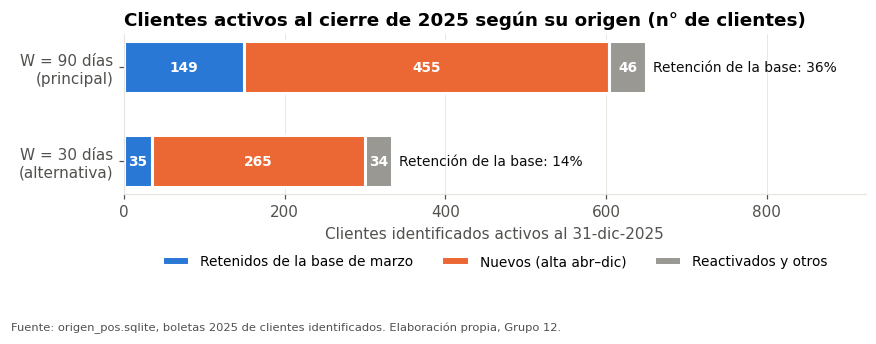

In [26]:
# G1 — Composición de la base activa al 31-dic según origen, bajo cada ventana
fig, ax = plt.subplots(figsize=(8, 3.1))
etiquetas = [f"W = {W_PRINCIPAL} días\n(principal)", f"W = {W_ALTERNATIVA} días\n(alternativa)"]
filas = [rp, ra]
partes = [("retenidos_31dic", "Retenidos de la base de marzo", AZUL),
          ("nuevos_activos_31dic", "Nuevos (alta abr–dic)", NARANJA),
          ("reactivados_u_otros_31dic", "Reactivados y otros", GRIS)]
for i, f in enumerate(filas):
    izq = 0
    for col, lab, colr in partes:
        v = f[col]
        ax.barh(i, v, left=izq, color=colr, height=0.55, edgecolor="white", linewidth=2,
                label=lab if i == 0 else None)
        if v > 25:
            ax.text(izq + v / 2, i, fmt_miles(v), ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        izq += v
    ax.text(izq + 8, i, f"Retención de la base: {f['RBA_pct']:.0f}%".replace(".", ","),
            va="center", color=TINTA, fontsize=9)
ax.set_yticks([0, 1], etiquetas)
ax.invert_yaxis()
ax.set_xlim(0, max(rp.activos_31dic, ra.activos_31dic) * 1.42)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Clientes identificados activos al 31-dic-2025")
ax.set_title("Clientes activos al cierre de 2025 según su origen (n° de clientes)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, fontsize=9)
guardar(fig, "G1_base_activa_31dic_por_origen")

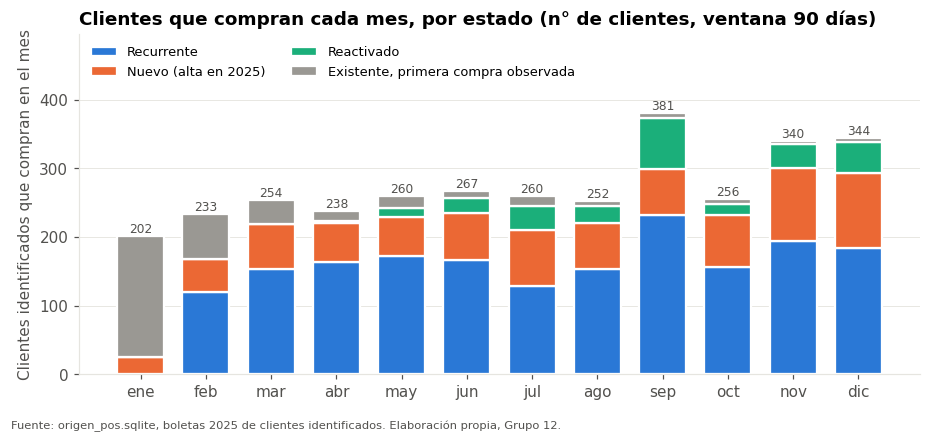

In [27]:
# G2 — Clientes que compran cada mes, por estado (W principal)
ident = ident.sort_values(["cliente_id", "fecha"])
ident["mes"] = ident["fecha"].dt.month
# Primera boleta de cada cliente en cada mes (drop_duplicates y no groupby.first, que salta nulos)
prim_mes = ident.drop_duplicates(["cliente_id", "mes"], keep="first").copy()
prim_mes["alta"] = prim_mes["cliente_id"].map(alta)

def estado(r, W=W_PRINCIPAL):
    if pd.isna(r["dias_desde_anterior"]):
        return "Nuevo (alta en 2025)" if r["alta"].year == ANIO else "Existente, primera compra observada"
    return "Recurrente" if r["dias_desde_anterior"] <= W else "Reactivado"

prim_mes["estado"] = prim_mes.apply(estado, axis=1)
flujo = prim_mes.pivot_table(index="mes", columns="estado", values="cliente_id", aggfunc="count", fill_value=0)
orden = [("Recurrente", AZUL), ("Nuevo (alta en 2025)", NARANJA), ("Reactivado", AQUA),
         ("Existente, primera compra observada", GRIS)]
flujo = flujo.reindex(columns=[o for o, _ in orden], fill_value=0)
flujo.to_csv(f"{TAB}/flujo_mensual_estados_w{W_PRINCIPAL}.csv")

fig, ax = plt.subplots(figsize=(8.5, 4))
base = np.zeros(12)
for col, colr in orden:
    ax.bar(flujo.index, flujo[col], bottom=base, color=colr, width=0.72, edgecolor="white", linewidth=1.5, label=col)
    base += flujo[col].values
for x, tot in zip(flujo.index, base):
    ax.text(x, tot + 5, fmt_miles(tot), ha="center", fontsize=8, color=TINTA2)
ax.set_xticks(range(1, 13), NOMBRE_MES)
ax.set_ylabel("Clientes identificados que compran en el mes")
ax.set_title(f"Clientes que compran cada mes, por estado (n° de clientes, ventana {W_PRINCIPAL} días)")
ax.legend(loc="upper left", fontsize=8.5, ncol=2)
ax.set_ylim(0, base.max() * 1.3)
ax.grid(axis="x", visible=False)
guardar(fig, "G2_flujo_mensual_por_estado")

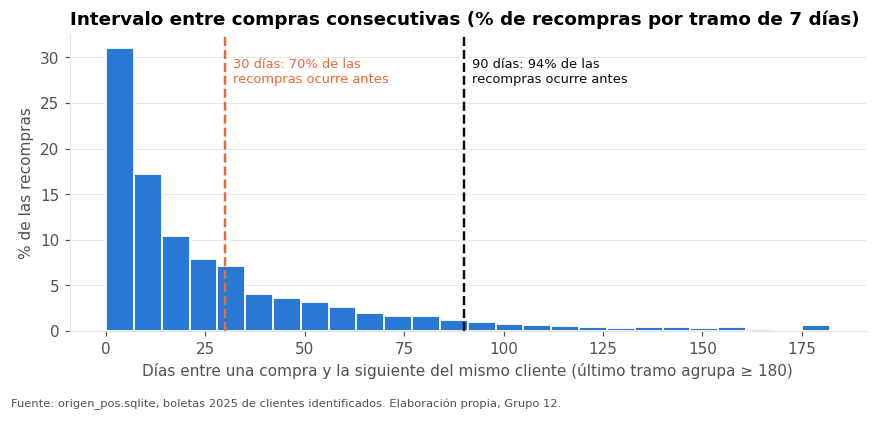

In [28]:
# G3 — Días entre compras consecutivas: justifica la ventana elegida
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.arange(0, 183, 7)
pesos = np.ones(len(gaps)) * 100 / len(gaps)
ax.hist(gaps.clip(upper=180), bins=bins, weights=pesos, color=AZUL, edgecolor="white", linewidth=1.2)
for W, colr in ((30, NARANJA), (90, TINTA)):
    ax.axvline(W, color=colr, linewidth=1.6, linestyle="--")
    ax.text(W + 2, ax.get_ylim()[1] * 0.92,
            f"{W} días: {pct_gap[W]:.0f}% de las\nrecompras ocurre antes".replace(".", ","),
            color=colr, fontsize=8.5, va="top")
ax.set_xlabel("Días entre una compra y la siguiente del mismo cliente (último tramo agrupa ≥ 180)")
ax.set_ylabel("% de las recompras")
ax.set_title("Intervalo entre compras consecutivas (% de recompras por tramo de 7 días)")
ax.grid(axis="x", visible=False)
guardar(fig, "G3_intervalo_entre_compras")

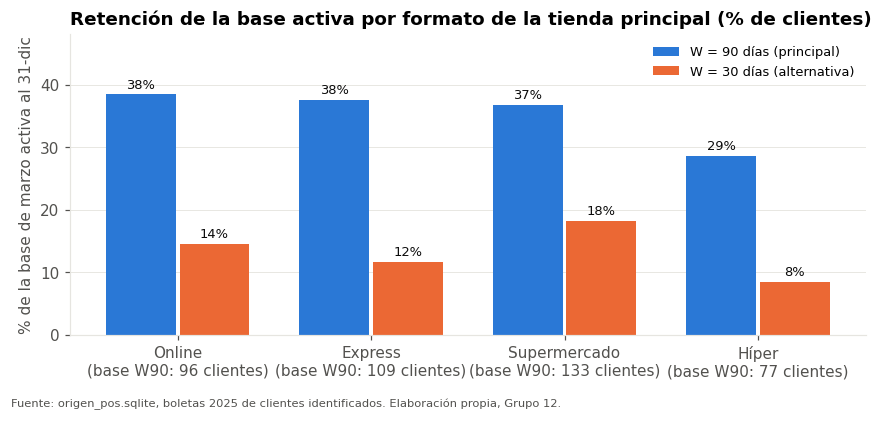

In [29]:
# G4 — Retención de la base por formato de la tienda principal
pf = por_formato.pivot(index="formato", columns="ventana_dias", values="RBA_pct")
nb = por_formato[por_formato["ventana_dias"] == W_PRINCIPAL].set_index("formato")["base_31mar"]
pf = pf.loc[pf[W_PRINCIPAL].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(pf))
ax.bar(x - 0.19, pf[W_PRINCIPAL], width=0.36, color=AZUL, label=f"W = {W_PRINCIPAL} días (principal)")
ax.bar(x + 0.19, pf[W_ALTERNATIVA], width=0.36, color=NARANJA, label=f"W = {W_ALTERNATIVA} días (alternativa)")
for xi, (v1, v2) in enumerate(zip(pf[W_PRINCIPAL], pf[W_ALTERNATIVA])):
    ax.text(xi - 0.19, v1 + 1, f"{v1:.0f}%", ha="center", fontsize=8.5, color=TINTA)
    ax.text(xi + 0.19, v2 + 1, f"{v2:.0f}%", ha="center", fontsize=8.5, color=TINTA)
ax.set_xticks(x, [f"{f}\n(base W90: {nb[f]} clientes)" for f in pf.index])
ax.set_ylabel("% de la base de marzo activa al 31-dic")
ax.set_ylim(0, max(pf.max()) * 1.25)
ax.set_title("Retención de la base activa por formato de la tienda principal (% de clientes)")
ax.legend(loc="upper right", fontsize=8.5)
ax.grid(axis="x", visible=False)
guardar(fig, "G4_retencion_por_formato")

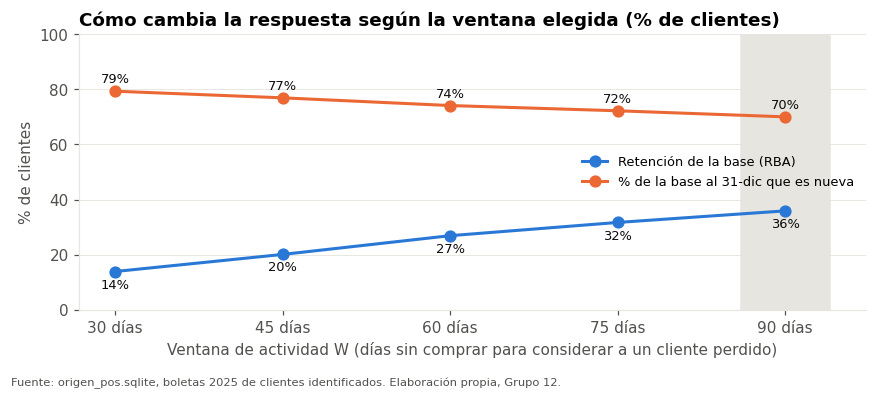

In [30]:
# G5 — Sensibilidad de la métrica a la ventana de actividad
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(sens["ventana_dias"], sens["RBA_pct"], color=AZUL, linewidth=2, marker="o", markersize=7, label="Retención de la base (RBA)")
ax.plot(sens["ventana_dias"], sens["pct_base_31dic_nueva"], color=NARANJA, linewidth=2, marker="o", markersize=7,
        label="% de la base al 31-dic que es nueva")
for _, r in sens.iterrows():
    ax.text(r.ventana_dias, r.RBA_pct - 6, f"{r.RBA_pct:.0f}%", ha="center", fontsize=8.5, color=TINTA)
    ax.text(r.ventana_dias, r.pct_base_31dic_nueva + 3, f"{r.pct_base_31dic_nueva:.0f}%", ha="center", fontsize=8.5, color=TINTA)
ax.axvspan(W_PRINCIPAL - 4, W_PRINCIPAL + 4, color=GRILLA, zorder=0)
ax.set_xticks(VENTANAS_SENSIBILIDAD, [f"{w} días" for w in VENTANAS_SENSIBILIDAD])
ax.set_ylim(0, 100)
ax.set_xlabel("Ventana de actividad W (días sin comprar para considerar a un cliente perdido)")
ax.set_ylabel("% de clientes")
ax.set_title("Cómo cambia la respuesta según la ventana elegida (% de clientes)")
ax.legend(loc="center right", fontsize=8.5)
ax.grid(axis="x", visible=False)
guardar(fig, "G5_sensibilidad_ventana")

### Diagrama del modelo dimensional
Se genera desde el código para que siempre coincida con las tablas que se construyen arriba.

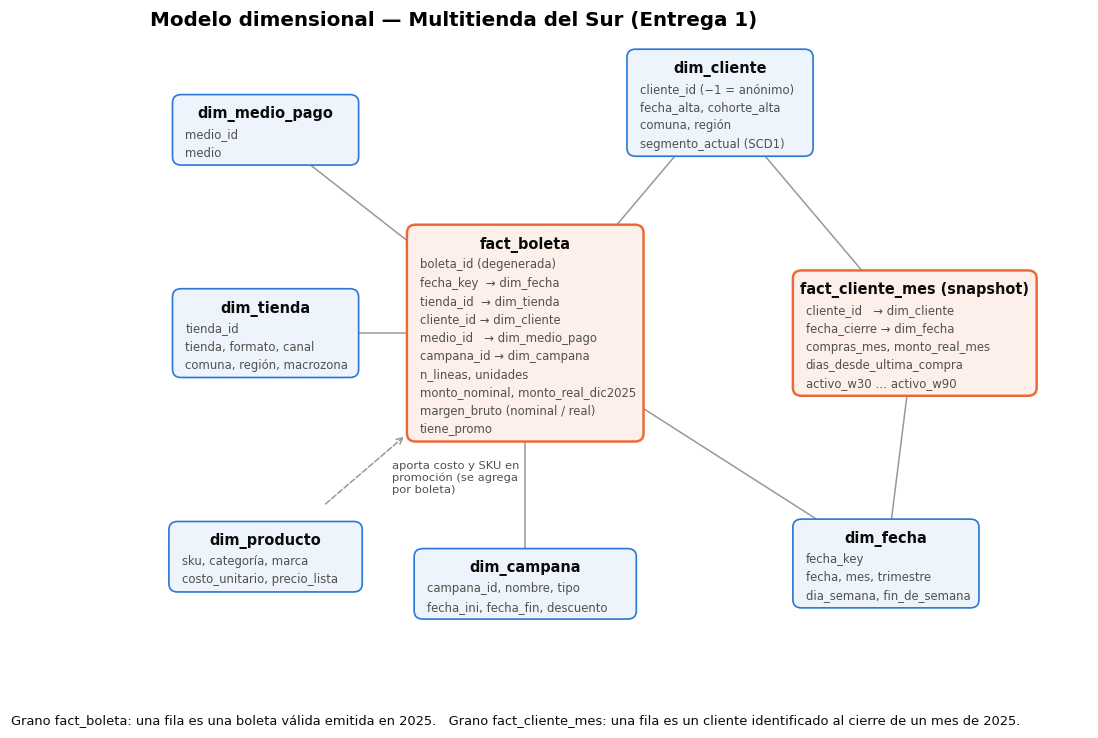

In [31]:
def caja(ax, x, y, titulo, campos, ancho=2.5, color="#eef4fc", borde=AZUL, hecho=False):
    alto = 0.42 + 0.27 * len(campos)
    ax.add_patch(matplotlib.patches.FancyBboxPatch((x - ancho / 2, y - alto / 2), ancho, alto,
                 boxstyle="round,pad=0.04,rounding_size=0.12", facecolor="#fdf0ea" if hecho else color,
                 edgecolor=NARANJA if hecho else borde, linewidth=1.6 if hecho else 1.1))
    ax.text(x, y + alto / 2 - 0.25, titulo, ha="center", va="center", fontsize=9.5, fontweight="bold", color=TINTA)
    for i, c in enumerate(campos):
        ax.text(x - ancho / 2 + 0.14, y + alto / 2 - 0.55 - 0.27 * i, c, fontsize=7.6, color=TINTA2, va="center")
    return (x, y)

fig, ax = plt.subplots(figsize=(11, 7.2))
ax.set_xlim(0, 13); ax.set_ylim(0, 9); ax.axis("off")
fb_c = caja(ax, 5.2, 4.6, "fact_boleta", ["boleta_id (degenerada)", "fecha_key  → dim_fecha", "tienda_id  → dim_tienda",
            "cliente_id → dim_cliente", "medio_id   → dim_medio_pago", "campana_id → dim_campana",
            "n_lineas, unidades", "monto_nominal, monto_real_dic2025", "margen_bruto (nominal / real)", "tiene_promo"],
            ancho=3.2, hecho=True)
fcm_c = caja(ax, 10.6, 4.6, "fact_cliente_mes (snapshot)", ["cliente_id   → dim_cliente", "fecha_cierre → dim_fecha",
             "compras_mes, monto_real_mes", "dias_desde_ultima_compra", "activo_w30 … activo_w90"], ancho=3.3, hecho=True)
dims = {
    "dim_fecha": (caja(ax, 10.2, 1.2, "dim_fecha", ["fecha_key", "fecha, mes, trimestre", "dia_semana, fin_de_semana"]), [fb_c, fcm_c]),
    "dim_tienda": (caja(ax, 1.6, 4.6, "dim_tienda", ["tienda_id", "tienda, formato, canal", "comuna, región, macrozona"]), [fb_c]),
    "dim_medio_pago": (caja(ax, 1.6, 7.6, "dim_medio_pago", ["medio_id", "medio"]), [fb_c]),
    "dim_cliente": (caja(ax, 7.9, 8.0, "dim_cliente", ["cliente_id (−1 = anónimo)", "fecha_alta, cohorte_alta",
                    "comuna, región", "segmento_actual (SCD1)"]), [fb_c, fcm_c]),
    "dim_campana": (caja(ax, 5.2, 0.9, "dim_campana", ["campana_id, nombre, tipo", "fecha_ini, fecha_fin, descuento"], ancho=3.0), [fb_c]),
    "dim_producto": (caja(ax, 1.6, 1.3, "dim_producto", ["sku, categoría, marca", "costo_unitario, precio_lista"], ancho=2.6), []),
}
for nombre, ((dx, dy), destinos) in dims.items():
    for (fx, fy) in destinos:
        ax.plot([dx, fx], [dy, fy], color=GRIS, linewidth=1, zorder=0)
ax.annotate("", xy=(3.55, 3.1), xytext=(2.4, 2.05), arrowprops=dict(arrowstyle="->", color=GRIS, linestyle="--"))
ax.text(3.35, 2.25, "aporta costo y SKU en\npromoción (se agrega\npor boleta)", fontsize=7.5, color=TINTA2, ha="left")
ax.set_title("Modelo dimensional — Multitienda del Sur (Entrega 1)", fontsize=13)
fig.text(0.01, 0.01, "Grano fact_boleta: una fila es una boleta válida emitida en 2025.   "
         "Grano fact_cliente_mes: una fila es un cliente identificado al cierre de un mes de 2025.",
         fontsize=8.5, color=TINTA)
fig.savefig(f"{DOCS}/modelo_dimensional.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## 8. Resumen de cifras del informe
Todas las cifras citadas en el informe salen de esta celda. Si el informe dice otra cosa, el informe está mal.

In [32]:
cifras = {
    "Boletas originales": n_boletas_orig,
    "Boletas válidas 2025": len(fact_boleta),
    "Boletas usadas en la métrica (identificadas)": n_en_metrica,
    "% de boletas originales excluidas de la métrica": cobertura.iloc[-2]["pct_sobre_originales"],
    "% de boletas válidas anónimas": round(100 * n_anon / len(boletas_validas), 1),
    "% de ventas válidas de clientes identificados": round(100 * pct_ventas_ident, 1),
    "Fuente IPC usada": FUENTE_IPC,
    "Inflación acumulada 2025 (%)": round(ipc["indice_dic2024_100"].iloc[-1] - 100, 2),
    "Mediana días entre compras": gaps.median(),
    "% recompras dentro de 30 / 60 / 90 días": f"{pct_gap[30]} / {pct_gap[60]} / {pct_gap[90]}",
    f"RBA W={W_PRINCIPAL} (%)": rp.RBA_pct,
    f"RBA W={W_ALTERNATIVA} (%)": ra.RBA_pct,
    f"Base activa 31-mar W={W_PRINCIPAL}": rp.base_activa_31mar,
    f"Clientes perdidos W={W_PRINCIPAL}": rp.perdidos,
    f"Nuevos activos 31-dic W={W_PRINCIPAL}": rp.nuevos_activos_31dic,
    f"% base 31-dic nueva W={W_PRINCIPAL}": rp.pct_base_31dic_nueva,
    f"Índice de reposición W={W_PRINCIPAL}": rp.indice_reposicion,
    f"Índice de reposición W={W_ALTERNATIVA}": ra.indice_reposicion,
    "Margen bruto promedio (%)": round(100 * margen_pct, 1),
    f"Ventas no capturadas abr-dic W={W_PRINCIPAL} ($ dic-2025)": int(caso.iloc[0]["ventas_no_capturadas_abr_dic"]),
    f"Margen no capturado abr-dic W={W_PRINCIPAL} ($ dic-2025)": int(caso.iloc[0]["margen_bruto_no_capturado_abr_dic"]),
    "Gasto anual real cliente recurrente ($)": round(gasto_rec),
    "Gasto anual real comprador de una vez ($)": round(gasto_unica),
}
cifras_df = pd.DataFrame(list(cifras.items()), columns=["cifra", "valor"])
cifras_df.to_csv(f"{TAB}/cifras_informe.csv", index=False)
print(f"Tiempo total de ejecución: {time.time() - T0:.0f} s")
cifras_df

Tiempo total de ejecución: 343 s


,cifra,valor
0,Boletas originales,6321
1,Boletas válidas 2025,6173
2,Boletas usadas en la métrica (identificadas),5369
3,% de boletas originales excluidas de la métrica,15.1
4,% de boletas válidas anónimas,13.0
5,% de ventas válidas de clientes identificados,93.5
6,Fuente IPC usada,API mindicador.cl
7,Inflación acumulada 2025 (%),3.44
8,Mediana días entre compras,14.0
9,% recompras dentro de 30 / 60 / 90 días,70.0 / 86.4 / 93.6
